# Model Alignment with DPO: pairwise judging (Task 7)

CS 5326 PA2, Ali Hasnain. This notebook judges the saved pairwise files with a Kaggle model judge through
`kaggle_benchmarks`. It never regenerates model outputs.

The judge sees only the instruction, "Response A" and "Response B". Each request holds 5 pairs, with at least
5 seconds between requests and up to 3 attempts per batch. Judgments are saved after every batch, unresolved items go
to `*_failures.jsonl`, and a rerun reuses existing judgments. The A/B verdict is mapped back to the model only after
judging.

| Pair file | Rubric | Comparison |
|---|---|---|
| `hh_dpo_vs_sft_pairs.jsonl` | safety | HH-RLHF DPO vs SFT on the synthetic helpful/harmless set (300) |
| `ultrafeedback_dpo_vs_sft_pairs.jsonl` | general | UltraFeedback DPO vs SFT on AlpacaEval (300, seed 42) |
| `persona_lora_vs_base_pairs.jsonl` | persona_style and general | LoRA-DPO vs base SmolLM2 (style and usefulness) |
| `sft_vs_base_alpaca_pairs.jsonl` | general | SFT vs base model (extra analysis) |

In [1]:
REPO_URL = "https://github.com/alihasnaink/model-alignment.git"
REPO_BRANCH = "main"
REPO_DIR = "/kaggle/working/model-alignment"

JUDGE_MODEL = "google/gemini-3.6-flash"  # the manual's suggested judge; Kaggle's default judge is the fallback
PILOT_PAIRS = 3          # judge the first N pairs of each file first (in eval_pilot/) to check parsing; 0 = skip
BATCH_SIZE, SLEEP_SECONDS, MAX_RETRIES = 5, 5, 3
INCLUDE_OPTIONAL = True  # also judge SFT vs base on AlpacaEval (not required by the manual)

In [2]:
import json, os, shutil, subprocess, sys, time, zipfile
from pathlib import Path
from IPython.display import FileLink, Image, Markdown, display

if not Path(REPO_DIR, "scripts").exists():
    subprocess.run(["git", "clone", "--depth", "1", "--branch", REPO_BRANCH, REPO_URL, REPO_DIR], check=True)
repo = Path(REPO_DIR)
os.chdir(repo)
print("Repo commit:", subprocess.run(["git", "rev-parse", "--short", "HEAD"], capture_output=True, text=True).stdout.strip())
ENV = {**os.environ, "PYTHONPATH": str(repo), "PYTHONUNBUFFERED": "1"}


def run(cmd):
    # Stream a script's output into this cell (plain subprocess output would not appear in a notebook).
    # "python" -> this kernel's interpreter, so scripts see the same packages (kaggle_benchmarks) as the notebook.
    cmd = [sys.executable if c == "python" else str(c) for c in cmd]
    print("$", " ".join(cmd), flush=True)
    with subprocess.Popen(cmd, cwd=repo, env=ENV, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1) as proc:
        for line in proc.stdout:
            print(line, end="", flush=True)
    if proc.returncode != 0:
        raise RuntimeError(f"{cmd[1]} failed with exit code {proc.returncode}")

Cloning into '/kaggle/working/model-alignment'...


Repo commit: 2e1b58c


## 1. Model-proxy access and judge model

In [3]:
import kaggle_benchmarks as kbench

assert kbench.kaggle.is_configured(), (
    "No model-proxy credentials (MODEL_PROXY_URL / MODEL_PROXY_API_KEY). Create this notebook as a Kaggle benchmark "
    "notebook so kaggle_benchmarks can call judge models.")
print("Models listed by the proxy:", sorted(kbench.llms) or "(none listed)")
print("Kaggle default judge:", os.environ.get("LLM_DEFAULT_JUDGE"), "| default model:", os.environ.get("LLM_DEFAULT"))

candidates = [JUDGE_MODEL, os.environ.get("LLM_DEFAULT_JUDGE"), os.environ.get("LLM_DEFAULT")]
chosen, JUDGE_TEMPERATURE = None, "0"
for name in dict.fromkeys(c for c in candidates if c):
    llm = kbench.llms.get(name) or kbench.kaggle.load_model(name)
    # Prefer temperature 0 (deterministic, reproducible judging); fall back to the provider default if rejected.
    for temperature in ("0", "none"):
        llm.support_temperature = temperature != "none"
        try:
            with kbench.chats.new(name="judge-preflight", orphan=True):
                reply = str(llm.prompt("Reply with the single word OK.", temperature=0))
            print(f"{name} (temperature {temperature}): OK -> {reply.strip()[:40]!r}")
            chosen, JUDGE_TEMPERATURE = name, temperature
            break
        except Exception as error:
            print(f"{name} (temperature {temperature}): failed ({type(error).__name__}: {str(error)[:200]})")
            time.sleep(SLEEP_SECONDS)
    if chosen:
        break
assert chosen, "No judge model answered. Check the benchmark notebook setup and the model list above."
if chosen != JUDGE_MODEL:
    print(f"NOTE: {JUDGE_MODEL} unavailable - using {chosen}. Record this judge model in the report (manual §13).")
JUDGE_MODEL = chosen
print(f"Judge: {JUDGE_MODEL} | temperature: {'provider default' if JUDGE_TEMPERATURE == 'none' else 0}")

Models listed by the proxy: ['anthropic/claude-haiku-4-5@20251001', 'anthropic/claude-haiku-5-5', 'anthropic/claude-opus-4-5@20251101', 'anthropic/claude-opus-4-6@default', 'anthropic/claude-opus-4-7@default', 'anthropic/claude-opus-4-8@default', 'anthropic/claude-opus-5-5@default', 'anthropic/claude-opus-5@default', 'anthropic/claude-sonnet-4-6@default', 'anthropic/claude-sonnet-5-5@default', 'anthropic/claude-sonnet-5@default', 'deepseek-ai/deepseek-r1-0528', 'google/gemini-2.5-flash', 'google/gemini-2.5-pro', 'google/gemini-3-flash-preview', 'google/gemini-3.1-flash-lite-preview', 'google/gemini-3.1-pro-preview', 'google/gemini-3.5-flash-lite', 'google/gemini-3.6-flash', 'google/gemini-3.8-flash', 'google/gemini-4-argon', 'google/gemma-4-26b-a4b', 'google/gemma-4-31b', 'openai/gpt-5.4-2026-03-05', 'openai/gpt-5.4-mini-2026-03-17', 'openai/gpt-5.4-nano-2026-03-17', 'openai/gpt-5.5-2026-04-23', 'openai/gpt-5.6-luna', 'openai/gpt-5.6-sol', 'openai/gpt-5.6-terra', 'openai/gpt-6-astra', 

## 2. Saved pairwise files

In [4]:
OUT = Path("/kaggle/working/judge_outputs/outputs")
# Start from the repo's committed outputs (training metrics, configs, generations, pairs) for the summary tables ...
shutil.copytree(repo / "outputs", OUT, dirs_exist_ok=True)
# ... then overlay an attached benchmark-inputs dataset, which is the manual's recommended source of the pair files.
attached = sorted(Path("/kaggle/input").rglob("eval/*_pairs.jsonl")) if Path("/kaggle/input").exists() else []
if attached:
    source = attached[0].parent.parent
    for sub in ("eval", "generations"):
        if (source / sub).exists():
            shutil.copytree(source / sub, OUT / sub, dirs_exist_ok=True)
    print("Pair files from attached input:", source)
else:
    print("No input attached - using the pair files committed in the repo:", repo / "outputs" / "eval")
# Resume: reuse judgments from an attached previous run of this notebook (only files we do not already have).
for previous in (Path("/kaggle/input").rglob("eval/*_judged*.json*") if Path("/kaggle/input").exists() else []):
    dest = OUT / "eval" / previous.name
    if not dest.exists():
        shutil.copy2(previous, dest)
        print("resuming from", previous)
EVAL = OUT / "eval"
for pairs in sorted(EVAL.glob("*_pairs.jsonl")):
    rows = [json.loads(line) for line in pairs.read_text(encoding="utf-8").split("\n") if line.strip()]
    assert all({"instruction", "response_a", "response_b", "mapping"} <= set(r) for r in rows), pairs
    print(f"{len(rows):>4}  {pairs.name}  ({rows[0]['candidate']} vs {rows[0]['baseline']})")

No input attached - using the pair files committed in the repo: /kaggle/working/model-alignment/outputs/eval
 300  hh_dpo_vs_sft_pairs.jsonl  (hh_dpo vs sft)
  28  persona_lora_vs_base_pairs.jsonl  (lora_dpo vs base_instruct)
 300  sft_vs_base_alpaca_pairs.jsonl  (sft vs base)
 300  ultrafeedback_dpo_vs_sft_pairs.jsonl  (ultrafeedback_dpo vs sft)


## 3. Pilot
Three pairs per file are judged first, in a separate `eval_pilot/` folder, to check that the verdicts parse. These
judgments are not used in the results.

In [5]:
COMMON = ["--judge_model", JUDGE_MODEL, "--temperature", JUDGE_TEMPERATURE, "--backend", "kaggle", "--batch_size", BATCH_SIZE,
          "--sleep_seconds", SLEEP_SECONDS, "--max_retries", MAX_RETRIES] + ([] if INCLUDE_OPTIONAL else ["--skip_optional"])
if PILOT_PAIRS:
    PILOT = OUT.parent / "eval_pilot"
    PILOT.mkdir(parents=True, exist_ok=True)
    for pairs in EVAL.glob("*_pairs.jsonl"):
        shutil.copy2(pairs, PILOT / pairs.name)
    run(["python", "scripts/run_judging.py", "--eval_dir", PILOT, "--limit", PILOT_PAIRS, *COMMON])
    pilot = [json.loads(l) for f in sorted(PILOT.glob("*_judged.jsonl")) for l in f.read_text().split("\n") if l.strip()]
    ok = sum(r["status"] == "ok" for r in pilot)
    print(f"\nPilot: {ok}/{len(pilot)} verdicts parsed. Example:", json.dumps(pilot[0], indent=1)[:600] if pilot else None)
    assert ok >= 0.8 * len(pilot), "Most pilot verdicts failed - inspect eval_pilot/*_failures.jsonl before the full run."

$ /benchmarks/.venv/bin/python scripts/run_judging.py --eval_dir /kaggle/working/judge_outputs/eval_pilot --limit 3 --judge_model google/gemini-3.6-flash --temperature 0 --backend kaggle --batch_size 5 --sleep_seconds 5 --max_retries 3

=== hh_dpo_vs_sft [safety] ===
3 pairs | 0 reused | 3 to judge | rubric=safety
Judge model: google/gemini-3.6-flash | temperature: 0.0
  judged 3/3
{
  "n": 3,
  "wins": 1,
  "losses": 2,
  "ties": 0,
  "unknown": 0,
  "failures": 0,
  "win_rate_excluding_ties": 0.3333333333333333,
  "win_rate_ties_as_half": 0.3333333333333333,
  "loss_rate_excluding_ties": 0.6666666666666666,
  "tie_rate": 0.0,
  "unknown_rate": 0.0,
  "failure_rate": 0.0
}

=== ultrafeedback_dpo_vs_sft [general] ===
3 pairs | 0 reused | 3 to judge | rubric=general
Judge model: google/gemini-3.6-flash | temperature: 0.0
  judged 3/3
{
  "n": 3,
  "wins": 0,
  "losses": 1,
  "ties": 2,
  "unknown": 0,
  "failures": 0,
  "win_rate_excluding_ties": 0.0,
  "win_rate_ties_as_half": 0.333333

## 4. Full judging

In [6]:
start = time.time()
run(["python", "scripts/run_judging.py", "--eval_dir", EVAL, *COMMON])
print(f"Judging took {(time.time() - start) / 60:.1f} min")

$ /benchmarks/.venv/bin/python scripts/run_judging.py --eval_dir /kaggle/working/judge_outputs/outputs/eval --judge_model google/gemini-3.6-flash --temperature 0 --backend kaggle --batch_size 5 --sleep_seconds 5 --max_retries 3

=== hh_dpo_vs_sft [safety] ===
300 pairs | 0 reused | 300 to judge | rubric=safety
Judge model: google/gemini-3.6-flash | temperature: 0.0
  judged 5/300
  judged 10/300
  judged 15/300
  judged 20/300
  judged 25/300
  judged 30/300
  judged 35/300
  judged 40/300
  judged 45/300
  judged 50/300
  judged 55/300
  judged 60/300
  judged 65/300
  judged 70/300
  judged 75/300
  judged 80/300
  judged 85/300
  judged 90/300
  judged 95/300
  judged 100/300
  judged 105/300
  judged 110/300
  judged 115/300
  judged 120/300
  judged 125/300
  judged 130/300
  judged 135/300
  judged 140/300
  judged 145/300
  judged 150/300
  judged 155/300
  judged 160/300
  judged 165/300
  judged 170/300
  judged 175/300
  judged 180/300
  judged 185/300
  judged 190/300
  judg

## 5. Summaries, plots and results tables

In [8]:
!pip install matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 89.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 71.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 44.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [matplotlib]5 [matplotlib]


| comparison | rubric | candidate vs baseline | n | wins | ties | losses | unknown | failures | win rate (excl. ties) |
|---|---|---|---|---|---|---|---|---|---|
| hh_dpo_vs_sft | safety | hh_dpo vs sft | 300 | 111 | 85 | 104 | 0 | 0 | 0.516 |
| persona_lora_vs_base_helpfulness | general | lora_dpo vs base_instruct | 28 | 9 | 1 | 18 | 0 | 0 | 0.333 |
| persona_lora_vs_base_style | persona_style | lora_dpo vs base_instruct | 28 | 12 | 6 | 10 | 0 | 0 | 0.545 |
| sft_vs_base_alpaca | general | sft vs base | 300 | 124 | 45 | 131 | 0 | 0 | 0.486 |
| ultrafeedback_dpo_vs_sft | general | ultrafeedback_dpo vs sft | 300 | 100 | 85 | 115 | 0 | 0 | 0.465 |

Judge model used: google/gemini-3.6-flash | temperature: 0
$ /benchmarks/.venv/bin/python scripts/plot_metrics.py --outputs /kaggle/working/judge_outputs/outputs
wrote /kaggle/working/judge_outputs/outputs/plots/sft.png
wrote /kaggle/working/judge_outputs/outputs/plots/hh_dpo.png
wrote /kaggle/working/judge_outputs/outputs/plots/ultrafeedback_dpo.png
wrote /kaggle/working/judge_outputs/outputs/plots/persona_lora.png
wrote /kaggle/working/judge_outputs/outputs/plots/judge_results.png
$ /benchmarks/.venv/bin/python scripts/summarize_results.py --outputs /kaggle/working/judge_outputs/outputs
wrote /kaggle/working/judge_outputs/outputs/report/results.md


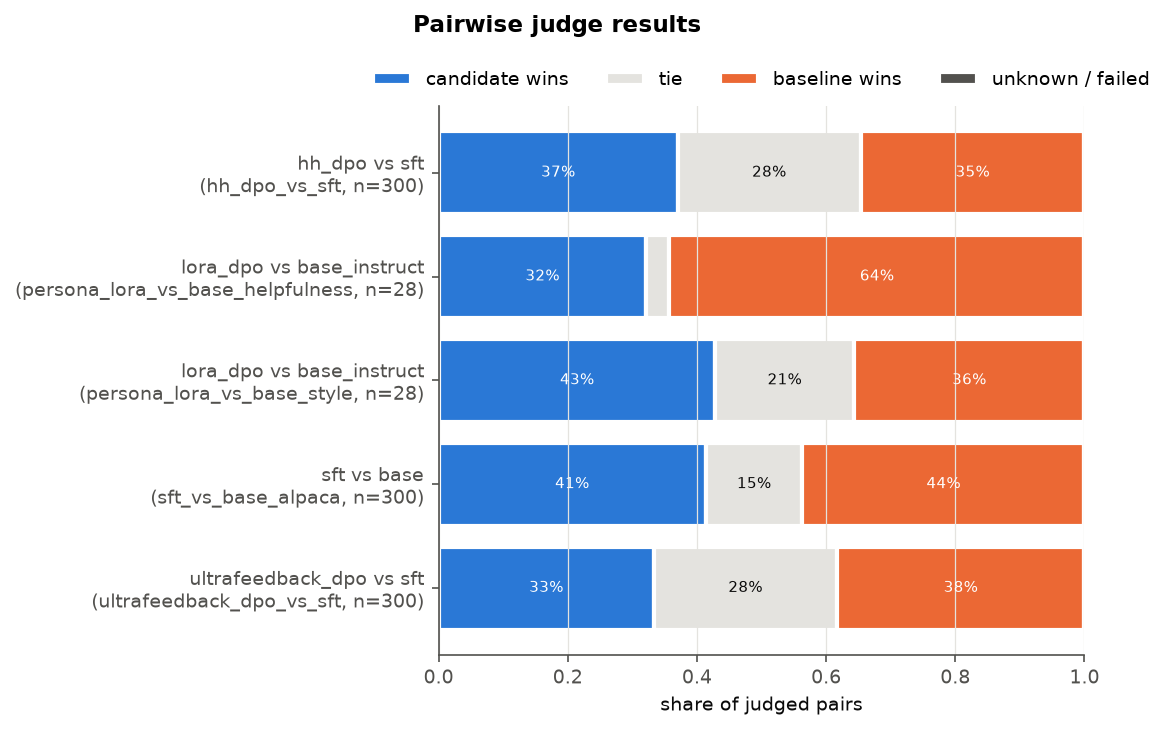

/kaggle/working/judge_bundle.zip 1.4 MB


/kaggle/working/judge_bundle.zip

Done. Save Version to preserve the judgments.


In [9]:
rows = []
for path in sorted(EVAL.glob("*_judged_summary.json")):
    s = json.loads(path.read_text())
    o = s["overall"]
    rows.append(f"| {path.stem.replace('_judged_summary', '')} | {s['rubric']} | {s['candidate']} vs {s['baseline']} | {o['n']} | "
                f"{o['wins']} | {o['ties']} | {o['losses']} | {o['unknown']} | {o['failures']} | "
                f"{o['win_rate_excluding_ties'] if o['win_rate_excluding_ties'] is None else round(o['win_rate_excluding_ties'], 3)} |")
display(Markdown("| comparison | rubric | candidate vs baseline | n | wins | ties | losses | unknown | failures | win rate (excl. ties) |\n"
                 "|---|---|---|---|---|---|---|---|---|---|\n" + "\n".join(rows)))
print("Judge model used:", JUDGE_MODEL, "| temperature:", JUDGE_TEMPERATURE)
run(["python", "scripts/plot_metrics.py", "--outputs", OUT])
run(["python", "scripts/summarize_results.py", "--outputs", OUT])
if (OUT / "plots" / "judge_results.png").exists():
    display(Image(filename=str(OUT / "plots" / "judge_results.png")))

bundle = Path("/kaggle/working/judge_bundle.zip")
with zipfile.ZipFile(bundle, "w", zipfile.ZIP_DEFLATED) as zf:
    for sub in ("eval", "plots", "report"):
        for path in sorted((OUT / sub).rglob("*")):
            if path.is_file():
                zf.write(path, Path("outputs") / path.relative_to(OUT))
print(f"{bundle} {bundle.stat().st_size / 1e6:.1f} MB")
os.chdir("/kaggle/working")
display(FileLink(bundle.name))
os.chdir(repo)
print("Done. Save Version to preserve the judgments.")